# OpenDengue — Global Dengue Case Counts

This notebook demonstrates the **`opendengue`** accessor for
[OpenDengue](https://opendengue.org/) — an open database of dengue case
counts collated from public surveillance sources across 100+ dengue-affected
countries, at national (Admin0), state/province (Admin1) and district
(Admin2) level, with some series back to 1924.

**License: CC BY 4.0 — citation is mandatory:**

> Clarke J, Lim A, Gupte P, Pigott DM, van Panhuis WG, Brady OJ.
> *A global dataset of publicly available dengue case count data.*
> Scientific Data 11, 296 (2024). https://doi.org/10.1038/s41597-024-03120-7

No API key is required; releases are versioned downloads from the
OpenDengue GitHub repository (cached locally, ~30-day TTL).

> **Note** — cells using the `highest_spatial` / `highest_temporal`
> extracts (~55 MB compressed, ~500 MB in memory) are shown but not
> executed in this copy. All `national`-level cells run live.

In [1]:
from epidatasets.sources.opendengue import OpenDengueAccessor, OpenDengueDataError

od = OpenDengueAccessor()  # optional: version="V1.3", cache_ttl_days=30
print(od.citation())

Clarke J, Lim A, Gupte P, Pigott DM, van Panhuis WG, Brady OJ. A global dataset of publicly available dengue case count data. Scientific Data. 2024;11(1):296. https://doi.org/10.1038/s41597-024-03120-7 (OpenDengue, CC BY 4.0, https://doi.org/10.6084/m9.figshare.24259573)


## 1. Countries covered

In [2]:
countries = od.list_countries()  # national extract
print(f"{len(countries)} countries")
countries.head(10)

129 countries


,country_name,country_code
0,AFGHANISTAN,AFG
1,AMERICAN SAMOA,ASM
2,ANGOLA,AGO
3,ANGUILLA,AIA
4,ANTIGUA AND BARBUDA,ATG
5,ARGENTINA,ARG
6,ARUBA,ABW
7,AUSTRALIA,AUS
8,BAHAMAS,BHS
9,BANGLADESH,BGD


## 2. The global national extract

One row per country-period, with the reporting window
(`calendar_start_date`/`calendar_end_date`), the case count
(`dengue_total`) and metadata about spatial/temporal resolution
(`S_res`/`T_res`).

In [3]:
national = od.get_global(level="national")
print(national.shape)
national[["adm_0_name", "calendar_start_date", "calendar_end_date",
          "dengue_total", "case_definition_standardised", "T_res"]].head()

(29873, 16)


,adm_0_name,calendar_start_date,calendar_end_date,dengue_total,case_definition_standardised,T_res
0,AFGHANISTAN,2021-09-05,2021-09-11,18.0,Suspected,Week
1,AFGHANISTAN,2021-09-12,2021-09-18,24.0,Suspected,Week
2,AFGHANISTAN,2021-09-19,2021-09-25,9.0,Suspected,Week
3,AFGHANISTAN,2021-09-26,2021-10-02,104.0,Suspected,Week
4,AFGHANISTAN,2021-10-03,2021-10-09,98.0,Suspected,Week


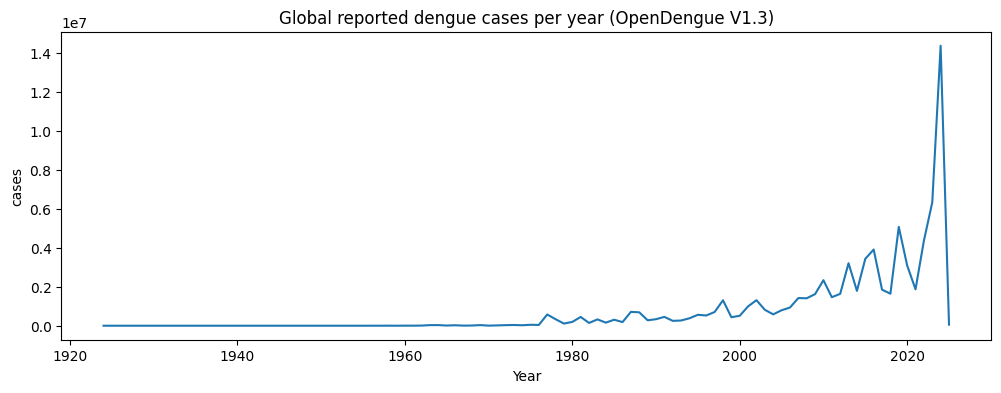

In [4]:
yearly = national.groupby("Year")["dengue_total"].sum()
ax = yearly.plot(figsize=(12, 4), title="Global reported dengue cases per year (OpenDengue V1.3)")
ax.set_ylabel("cases");

## 3. Country series with fuzzy matching and ISO3 codes

In [5]:
# country lookup accepts names (case/accent-insensitive + fuzzy) and ISO3 codes
bra = od.get_country("Brasil", level="national")   # fuzzy -> BRAZIL
print(bra["calendar_start_date"].min(), "->", bra["calendar_start_date"].max())
bra[["adm_0_name", "calendar_start_date", "dengue_total"]].tail()

1980-01-01 00:00:00 -> 2024-01-01 00:00:00


,adm_0_name,calendar_start_date,dengue_total
450,BRAZIL,2023-12-10,40789.0
451,BRAZIL,2023-12-17,38305.0
452,BRAZIL,2023-12-24,2146.0
453,BRAZIL,2023-12-31,82978.0
454,BRAZIL,2024-01-01,10267077.0


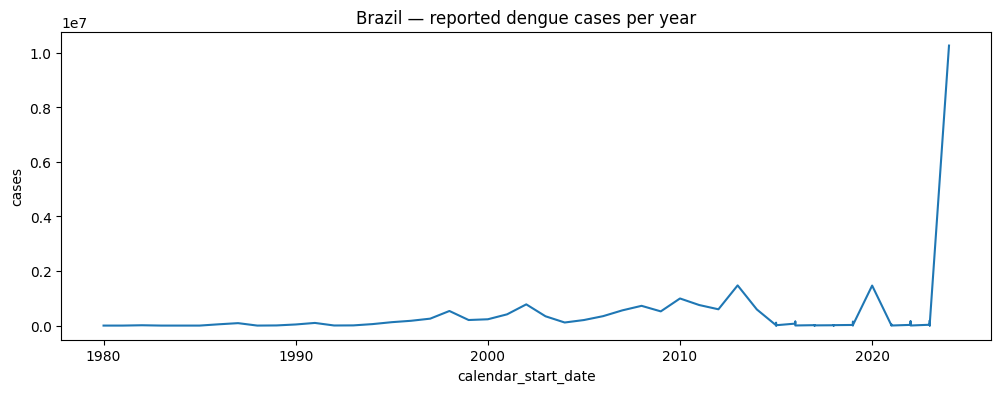

In [6]:
bra_yearly = bra.set_index(bra["calendar_start_date"].dt.year)["dengue_total"]
ax = bra_yearly.plot(figsize=(12, 4), title="Brazil — reported dengue cases per year")
ax.set_ylabel("cases");

## 4. The 2024 dengue epidemic in the Americas

In [7]:
recent = od.get_global(level="national")
recent = recent[recent["Year"] == 2024]
top = (recent.groupby("adm_0_name")["dengue_total"].sum()
       .sort_values(ascending=False).head(12))
top

adm_0_name
BRAZIL       10267077.0
ARGENTINA      581559.0
MEXICO         558846.0
COLOMBIA       320982.0
PARAGUAY       295785.0
PERU           280726.0
INDIA          233519.0
INDONESIA      210644.0
GUATEMALA      188585.0
HONDURAS       177209.0
MALAYSIA       122423.0
VIET NAM       108433.0
Name: dengue_total, dtype: float64

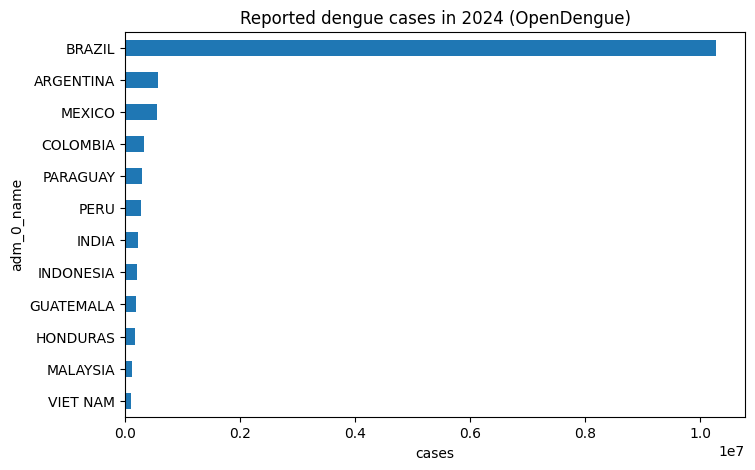

In [8]:
ax = top.sort_values().plot.barh(figsize=(8, 5), title="Reported dengue cases in 2024 (OpenDengue)")
ax.set_xlabel("cases");

## 5. Subnational detail (highest spatial resolution)

The `highest_spatial` extract carries the finest available spatial
resolution per country (Admin1/Admin2) — ~500 MB in memory. Use
`admin_level` to restrict rows, and `get_timeseries` to pick one
location.

In [ ]:
# ~55 MB download, ~500 MB DataFrame (not executed here)
states = od.get_country("Brazil", admin_level=1, level="highest_spatial")
states[["adm_1_name", "calendar_start_date", "dengue_total"]].head()

In [ ]:
# one location's series (accent/case-insensitive admin names)
rj = od.get_timeseries("Brazil", admin1="Rio de Janeiro", level="highest_spatial")
rj[["adm_1_name", "calendar_start_date", "dengue_total"]].tail(12)

## 6. Date-range filtering (overlap semantics)

In [ ]:
# rows are kept when their reporting period overlaps the requested window
epi = od.get_country("Brazil", start_date="2024-01-01", end_date="2024-06-30",
                     level="national")
epi.groupby(epi["calendar_start_date"].dt.month)["dengue_total"].sum()

## 7. Underlying data sources

In [ ]:
sources = od.get_sources()          # one row per country
sources.head(10)

In [ ]:
india = od.get_sources(country="India")
india

## 8. Error handling

In [9]:
try:
    od.get_country("Narnia", level="national")
except OpenDengueDataError as e:
    print("OpenDengueDataError:", e)

OpenDengueDataError: Country 'Narnia' not found in OpenDengue. Closest matches: none. Use list_countries() to see all available names.


## 9. Using the plugin registry

In [10]:
from epidatasets import get_source

acc = get_source("opendengue")
acc.list_countries().head()

,country_name,country_code
0,AFGHANISTAN,AFG
1,AMERICAN SAMOA,ASM
2,ANGOLA,AGO
3,ANGUILLA,AIA
4,ANTIGUA AND BARBUDA,ATG


## References

- OpenDengue website: https://opendengue.org/
- GitHub releases: https://github.com/OpenDengue/master-repo
- Figshare DOI: https://doi.org/10.6084/m9.figshare.24259573
- Publication: https://doi.org/10.1038/s41597-024-03120-7